# Computation of PSF

Histogram dependent on energy and inclination angle theta. Fit with double King

## Imports

In [1]:
import ROOT, glob, os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

cling::DynamicLibraryManager::loadLibrary(): libOpenGL.so.0: cannot open shared object file: No such file or directory
Error in <AutoloadLibraryMU>: Failed to load library /cvmfs/sft.cern.ch/lcg/releases/ROOT/6.28.04-740f6/x86_64-el9-gcc11-opt/lib/libEve.socling JIT session error: Failed to materialize symbols: { (main, { _ZeqRK7TStringRKNSt7__cxx1112basic_stringIcSt11char_traitsIcESaIcEEE }) }


Welcome to JupyROOT 6.28/04


## Load data : one file

In [2]:
# dirDir= "/home/users/l/lebrun/"
# resultPath = dirDir + "results/"
# figPath = dirDir + "figures/"
# dataPath = dirDir + "data/"

# try :
#     os.mkdir(figPath+"PSF")
# except FileExistsError:
#     pass

# exponent = -2.5
# figPath = figPath+f"PSF/exp{exponent:.1f}/"
# df = pd.read_csv(dataPath + f"MC_het_exp{exponent:.1f}_filtered_angle.csv")
# nbins = 50

# df = df[df['tt_isHET'] == 1]

## Load data per bin

In [3]:
def browse_files(filenames):
    """
    Browse through the list of filenames and return a sorted list of files.
    """
    if isinstance(filenames, str):
        files = sorted(glob.glob(filenames))
    elif isinstance(filenames, list):
        files = []
        for filename in filenames:
            files += sorted(glob.glob(filename))
    else:
        raise ValueError("Input should be a string or a list of strings.")
    
    return files

In [4]:
dirDir= "/home/users/l/lebrun/"
dataPath = "/dpnc/beegfs/dampe/tryf/ForKimberly/"
exponent = 0
figPath = dirDir + "figures/"
figPath = figPath+f"PSF/exp{exponent:.1f}/"
resPath = dirDir + "results/"

dataPath_filtered = dataPath + "tt_filtered" + "_cos_theta_bins/"
dataPath_filtered += f"exp{exponent:.1f}/"

files_filtered = browse_files(dataPath_filtered + "*.root")
print(f"Loading files: {files_filtered}")

rdf_filtered = ROOT.RDataFrame("MC", files_filtered)
# Extract only desired columns
df = rdf_filtered.AsNumpy(["tt_ekin", "tt_theta", "tt_phi", "weight", "tt_isHET", "theta_BestSTK", "phi_BestSTK"])
df = pd.DataFrame(df)

nbins = 50

Loading files: ['/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_0.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_1.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_10.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_11.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_12.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_13.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_14.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_15.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/filtered_costheta_bin_16.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_

In [5]:
df['Etrue'] = df['tt_ekin'] * 1e-3

df = df[df['Etrue'] <= 1e4]

df= df.rename(columns={'tt_theta' : 'theta_True', 'tt_phi' : 'phi_True'})

df['theta_True_deg']= np.rad2deg(df['theta_True'])
df['phi_True_deg']= np.rad2deg(df['phi_True'])
df['theta_BestSTK_deg']= df['theta_BestSTK']
df['phi_BestSTK_deg']= df['phi_BestSTK']

In [6]:

print("Full DataFrame loaded:", df.shape)
print(f"Theta ranges from {df['theta_BestSTK'].min()} to {df['theta_BestSTK'].max()} deg")
print(f"Phi ranges from {df['phi_BestSTK'].min()} to {df['phi_BestSTK'].max()} deg")
print(f"phi True ranges from {df['phi_True'].min()} to {df['phi_True'].max()} deg")
print(f"Theta True ranges from {df['theta_True'].min()} to {df['theta_True'].max()} deg")

print(f"Energy ranges from {df['Etrue'].min()} to {df['Etrue'].max()} GeV")

Full DataFrame loaded: (175751, 12)
Theta ranges from 0.1513029306574977 to 59.9840666092781 deg
Phi ranges from -179.99964649681542 to 179.99999999999977 deg
phi True ranges from -3.141541123480502 to 3.141573260697711 deg
Theta True ranges from 0.0014336268100510286 to 1.5621901719043787 deg
Energy ranges from 1.3416552397116572 to 9998.562154091216 GeV


In [7]:
df['theta_BestSTK'] = np.deg2rad(df['theta_BestSTK'])
df['phi_BestSTK'] = np.deg2rad(df['phi_BestSTK'])
# df['theta_True'] = np.deg2rad(df['theta_True'])
# df['phi_True'] = np.deg2rad(df['phi_True'])
print(f"DEBUG : before filtering, {len(df)} entries")
df = df[(df['theta_True'] > 1e-7) & (df['theta_BestSTK'] > 1e-7)]
print(f"DEBUG : after filtering, {len(df)} entries")

DEBUG : before filtering, 175751 entries
DEBUG : after filtering, 175751 entries


## Explore branches

In [8]:
print("Full DataFrame pre-processed:", df.shape)

print(f"Theta ranges from {df['theta_BestSTK'].min()} to {df['theta_BestSTK'].max()} rad")
print(f"Phi ranges from {df['phi_BestSTK'].min()} to {df['phi_BestSTK'].max()} rad")
print(f"phi True ranges from {df['phi_True'].min()} to {df['phi_True'].max()} rad")
print(f"Theta True ranges from {df['theta_True'].min()} to {df['theta_True'].max()} rad")

print(f"Energy ranges from {df['Etrue'].min()} to {df['Etrue'].max()} GeV")

Full DataFrame pre-processed: (175751, 12)
Theta ranges from 0.0026407343078900035 to 1.046919461067494 rad
Phi ranges from -3.141586483795306 to 3.141592653589789 rad
phi True ranges from -3.141541123480502 to 3.141573260697711 rad
Theta True ranges from 0.0014336268100510286 to 1.5621901719043787 rad
Energy ranges from 1.3416552397116572 to 9998.562154091216 GeV


## Compute angular error 

In [9]:
def angular_error(theta_true, phi_true, theta_reco, phi_reco):

    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # # Compute dot product and then angle between vectors
    dot = np.sum(v_true * v_reco, axis=-1)
    dot = np.clip(dot, -1.0, 1.0)
    mask = np.abs(dot) > 1
    if np.any(mask):
        print(f"ERROR: Found {np.sum(mask)} dot products not in [-1, 1]")
        print("Examples:", dot[mask][:5])  # print first 5 bad values

    angle_rad = np.arccos(dot)

    # delta_v = v_true - v_reco
    # delta_v_norm = np.linalg.norm(delta_v, axis=-1)

    return angle_rad

def angular_error_2(theta_true, phi_true, theta_reco, phi_reco):

    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # # Compute dot product and then angle between vectors
    # dot = np.sum(v_true * v_reco, axis=-1)
    # mask = np.abs(dot) > 1
    # if np.any(mask):
    #     print(f"ERROR: Found {np.sum(mask)} dot products not in [-1, 1]")
    #     print("Examples:", dot[mask][:5])  # print first 5 bad values

    # angle_rad = np.arccos(dot)

    delta_v = v_true - v_reco
    delta_v_norm = np.linalg.norm(delta_v, axis=-1)

    return delta_v_norm

def error_xyz(theta_true, phi_true, theta_reco, phi_reco):
    # Convert spherical to Cartesian coordinates
    def sph2cart(theta, phi):
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)
        return np.stack((x, y, z), axis=-1)

    v_true = sph2cart(theta_true, phi_true)
    v_reco = sph2cart(theta_reco, phi_reco)

    # Compute the difference in Cartesian coordinates
    delta_v = v_true - v_reco

    return delta_v

test1 = angular_error(0.2, 0.2, 0.3, 0.4)
test2 = angular_error_2(0.2, 0.2, 0.3, 0.4)
print("Angular error test:", test1)
print("Angular error test 2:", test2)


Angular error test: 0.11110795869098433
Angular error test 2: 0.11105081645279716


In [10]:
df['angular_error'] = angular_error(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])

df['angular_error_degrees'] = df['angular_error'] * 180 / np.pi

# Count outliers
outliers = df[(df['angular_error_degrees'] > 10)]
print("Outliers count:", outliers.shape[0])
print("Outliers proportion : ", outliers.shape[0] / df.shape[0] *100, "%")

df = df[(df['angular_error_degrees'] < 10)].copy()

df['cosTheta'] = np.cos(df['theta_True'])
df = df.loc[df["cosTheta"] >= 0.5]

angular_error_2_test = angular_error_2(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])
angular_error_2_test = angular_error_2_test * 180 / np.pi

diff_angular_errors = df["angular_error_degrees"] - angular_error_2_test
print("Mean angular error difference:", diff_angular_errors.mean())
print("Median angular error difference:", diff_angular_errors.median())
print("Max angular error difference:", diff_angular_errors.max())
print("Min angular error difference:", diff_angular_errors.min())
print("Standard deviation angular error difference:", diff_angular_errors.std())
print("Maximum angular error method 1:", df["angular_error_degrees"].max())
print("Maximum angular error method 2:", angular_error_2_test.max())
print("Minimum angular error method 1:", df["angular_error_degrees"].min())
print("Minimum angular error method 2:", angular_error_2_test.min())

Outliers count: 5906
Outliers proportion :  3.360436071487502 %


Mean angular error difference: 8.045142215805881e-05
Median angular error difference: 4.687532313696341e-09
Max angular error difference: 0.012663692294317741
Min angular error difference: -2.2063738349770113e-09
Standard deviation angular error difference: 0.0006699978343926561
Maximum angular error method 1: 9.993723718673975
Maximum angular error method 2: 9.981060026379657
Minimum angular error method 1: 9.200574751340626e-05
Minimum angular error method 2: 9.200795388724124e-05


## Study potential biases in xyz

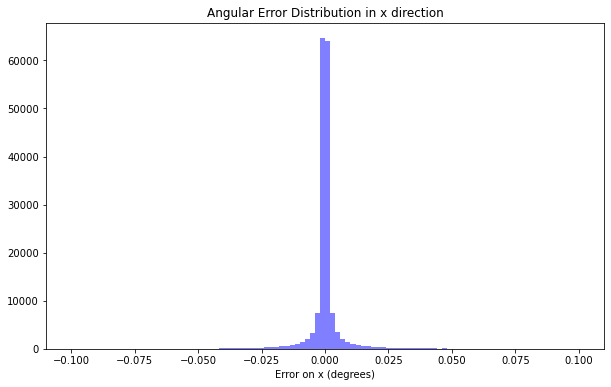

In [11]:
errors_xyz = error_xyz(df['theta_True'], df['phi_True'], df['theta_BestSTK'], df['phi_BestSTK'])

# Plot histograms of the angular errors
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 0], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='blue')
plt.title('Angular Error Distribution in x direction')
plt.xlabel('Error on x (degrees)')
plt.show()


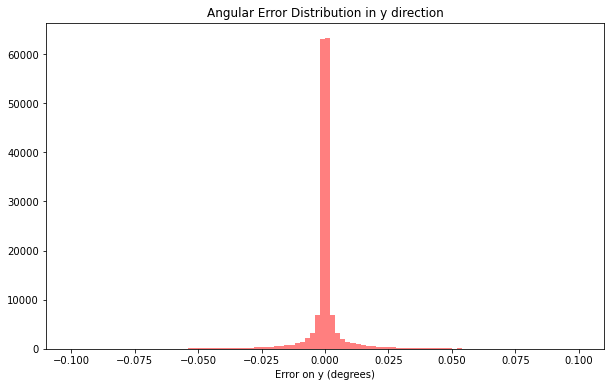

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 1], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='red')
plt.title('Angular Error Distribution in y direction')
plt.xlabel('Error on y (degrees)')
plt.show()


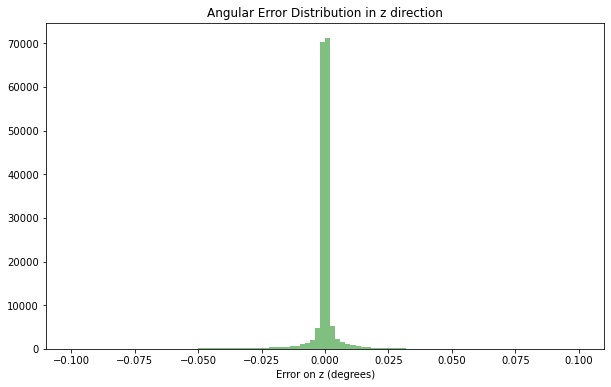

In [13]:
plt.figure(figsize=(10, 6))
plt.hist(errors_xyz[:, 2], bins=100, range=(-0.1, 0.1), alpha=0.5, label='Angular Error (degrees)', color='green')
plt.title('Angular Error Distribution in z direction')
plt.xlabel('Error on z (degrees)')
plt.show()


## Study error on theta and phi

In [14]:
theta_diff = df['theta_BestSTK'] - df['theta_True']
phi_diff = df['phi_BestSTK'] - df['phi_True']


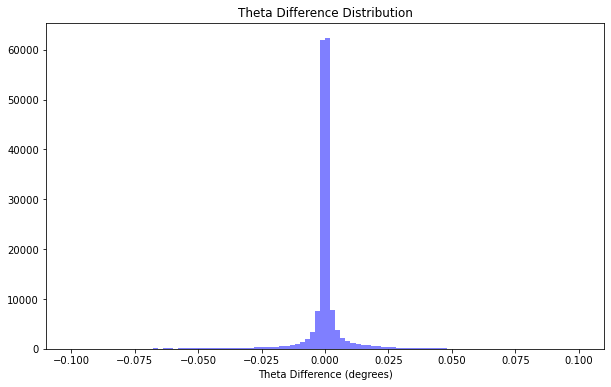

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(theta_diff, bins=100, range=(-0.1, 0.1), alpha=0.5, label='Theta Difference', color='blue')
plt.title('Theta Difference Distribution')
plt.xlabel('Theta Difference (degrees)')
plt.show()


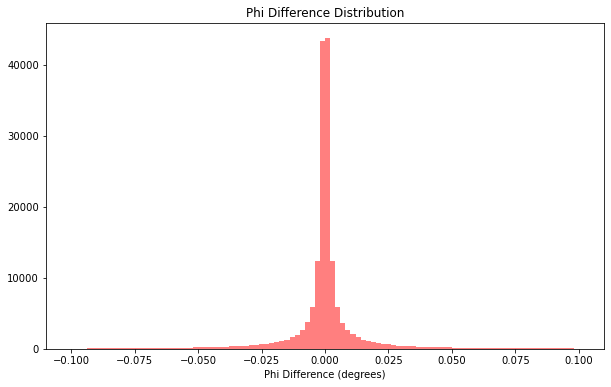

In [16]:
plt.figure(figsize=(10, 6))
plt.hist(phi_diff, bins=100, range=(-0.1, 0.1), alpha=0.5, label='Phi Difference', color='red')
plt.title('Phi Difference Distribution')
plt.xlabel('Phi Difference (degrees)')
plt.show()

## Angular error (absolute value)

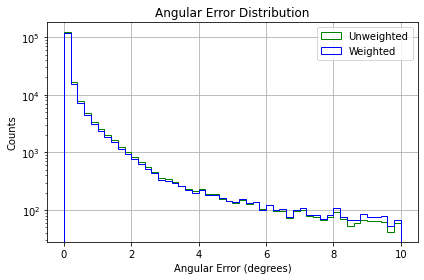

In [17]:
fig, ax = plt.subplots()

range_ = (0, 10)
column = 'angular_error_degrees'

# --- Unweighted histogram ---
ax.hist(df[column], bins=nbins, range=range_, histtype='step', color='green', label='Unweighted')
ax.hist(df[column], bins=nbins, range=range_, weights=df['weight'],
            histtype='step', color='blue', label='Weighted')
ax.set_title('Angular Error Distribution')
ax.set_xlabel('Angular Error (degrees)')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.legend()
ax.grid(True)


plt.tight_layout()
fig.savefig(figPath + f"angular_error_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()


## Plot difference between theta true and reconstructed

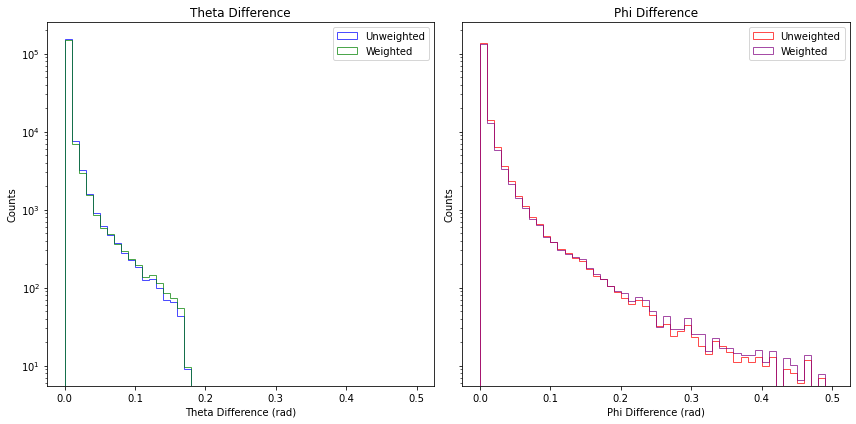

In [18]:
df["thetaDiff"] = df["theta_BestSTK"] - df["theta_True"]
df["phiDiff"] = df["phi_BestSTK"] - df["phi_True"]
df["thetaDiff"] = df["thetaDiff"].abs()
df["phiDiff"] = df["phiDiff"].abs()

# Plot histograms of the differences
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["thetaDiff"], bins=nbins, histtype='step', range=(0, 0.5), color='blue', alpha=0.7, label='Unweighted')
ax[0].hist(df["thetaDiff"], weights=df['weight'], bins=nbins, histtype='step', range=(0, 0.5), color='green', alpha=0.7, label='Weighted')
ax[0].set_title("Theta Difference")
ax[0].set_xlabel("Theta Difference (rad)")
ax[0].set_ylabel("Counts")
ax[0].set_yscale('log')
ax[0].legend()
ax[1].hist(df["phiDiff"], bins=nbins, range=(0, 0.5), histtype='step', color='red', alpha=0.7, label='Unweighted')
ax[1].hist(df["phiDiff"], weights=df['weight'], bins=nbins, range=(0, 0.5), histtype='step', color='purple', alpha=0.7, label='Weighted')
ax[1].set_title("Phi Difference")
ax[1].set_xlabel("Phi Difference (rad)")
ax[1].set_ylabel("Counts")
ax[1].set_yscale('log')
ax[1].legend()
plt.tight_layout()
fig.savefig(figPath + f"theta_phi_difference_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()

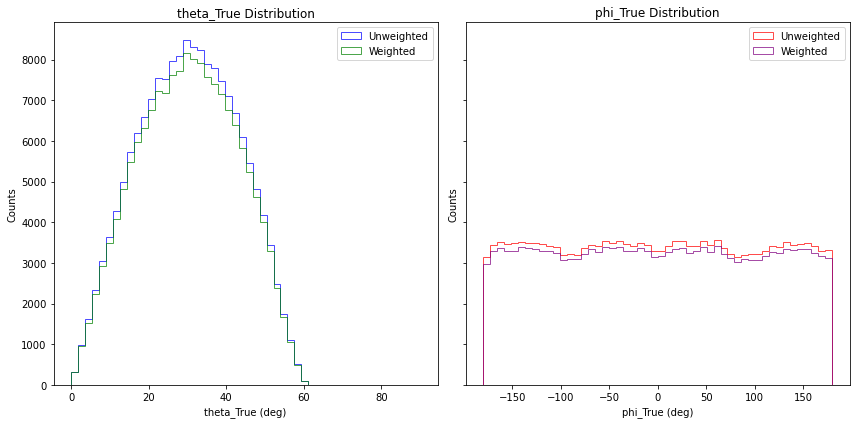

In [19]:
# Plot the distribution of theta_True and phi_True
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["theta_True_deg"], bins=nbins, range=(0, 90), color='blue', alpha=0.7, histtype='step', label='Unweighted')
ax[0].hist(df["theta_True_deg"], weights=df['weight'], bins=nbins, range=(0, 90), color='green', alpha=0.7, histtype='step', label='Weighted')
ax[0].set_title("theta_True Distribution")
ax[0].set_xlabel("theta_True (deg)")
ax[0].set_ylabel("Counts")
ax[0].legend()
ax[1].hist(df["phi_True_deg"], bins=nbins, range=(-180, 180), color='red', alpha=0.7, histtype='step', label='Unweighted')
ax[1].hist(df["phi_True_deg"], weights=df['weight'], bins=nbins, range=(-180, 180), color='purple', alpha=0.7, histtype='step', label='Weighted')
ax[1].set_title("phi_True Distribution")
ax[1].set_xlabel("phi_True (deg)")
ax[1].set_ylabel("Counts")
ax[1].legend()
plt.tight_layout()
fig.savefig(figPath + f"theta_phi_true_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()

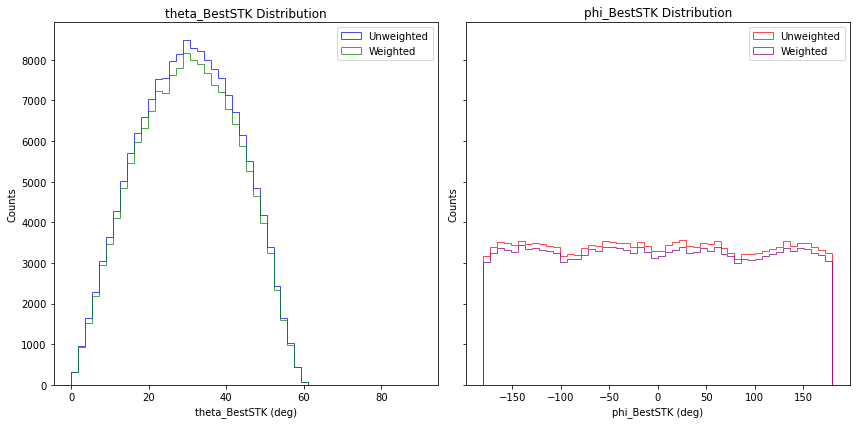

In [20]:
# Plot the distribution of theta_True and phi_True
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["theta_BestSTK_deg"], bins=nbins, range=(0, 90), color='blue', alpha=0.7, histtype='step', label='Unweighted')
ax[0].hist(df["theta_BestSTK_deg"], weights=df['weight'], bins=nbins, range=(0, 90), color='green', alpha=0.7, histtype='step', label='Weighted')
ax[0].set_title("theta_BestSTK Distribution")
ax[0].set_xlabel("theta_BestSTK (deg)")
ax[0].set_ylabel("Counts")
ax[0].legend()
ax[1].hist(df["phi_BestSTK_deg"], bins=nbins, range=(-180, 180), color='red', alpha=0.7, histtype='step', label='Unweighted')
ax[1].hist(df["phi_BestSTK_deg"], weights=df['weight'], bins=nbins, range=(-180, 180), color='purple', alpha=0.7, histtype='step', label='Weighted')
ax[1].set_title("phi_BestSTK Distribution")
ax[1].set_xlabel("phi_BestSTK (deg)")
ax[1].set_ylabel("Counts")
ax[1].legend()
plt.tight_layout()
fig.savefig(figPath + f"theta_phi_beststk_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()

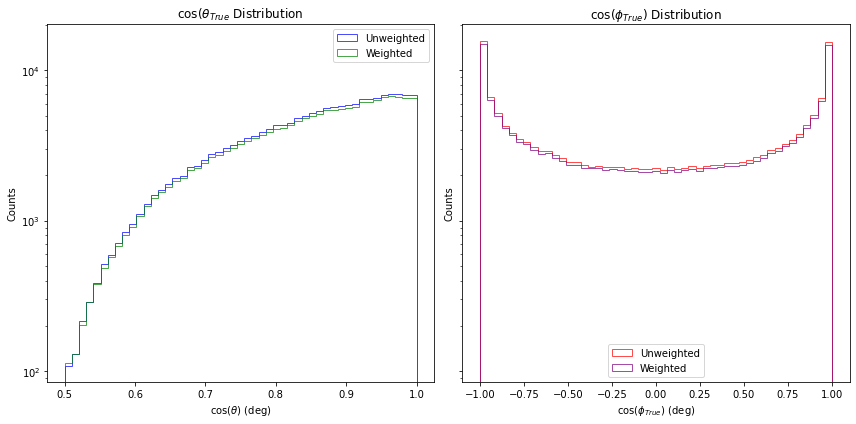

In [41]:
bins_cosTheta = np.linspace(0.5, 1, nbins)
bins_cosPhi = np.linspace(-1, 1, nbins)
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
ax[0].hist(df["cosTheta"], bins=bins_cosTheta, color='blue', alpha=0.7, histtype='step', label='Unweighted')
ax[0].hist(df["cosTheta"], weights=df['weight'], bins=bins_cosTheta, color='green', alpha=0.7, histtype='step', label='Weighted')
ax[0].set_title("$\cos(\\theta_{True}})$ Distribution")
ax[0].set_xlabel("$\cos(\\theta)$ (deg)")
ax[0].set_ylabel("Counts")
ax[0].set_yscale('log')
ax[0].legend()
ax[1].hist(np.cos(df["phi_True_deg"]), bins=bins_cosPhi, color='red', alpha=0.7, histtype='step', label='Unweighted')
ax[1].hist(np.cos(df["phi_True_deg"]), weights=df['weight'], bins=bins_cosPhi, color='purple', alpha=0.7, histtype='step', label='Weighted')
ax[1].set_title("$\cos(\phi_{True})$ Distribution")
ax[1].set_xlabel("$\cos(\phi_{True})$ (deg)")
ax[1].set_ylabel("Counts")
ax[1].set_yscale('log')
ax[1].legend()
plt.tight_layout()
fig.savefig(figPath + f"costheta_cosphi_true_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()

In [42]:

bins = np.logspace(np.log10(0.01), np.log10(5), 100)  # from 0.01° to 5°, 100 bins

# Compute histogram
counts, bin_edges = np.histogram(df['angular_error_degrees'], bins=bins)
counts_w, _ = np.histogram(df['angular_error_degrees'], bins=bins, weights=df['weight'])

# Compute bin centers
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])  # geometric mean for log bins

density = counts / np.sum(counts)  # normalize to get density
density_w = counts_w / np.sum(counts_w)  # normalize to get weighted density

integral = np.trapz(density_w, bin_centers)
print(f"Integral of PSF_bar: {integral}") 

Integral of PSF_bar: 0.018862244942075758


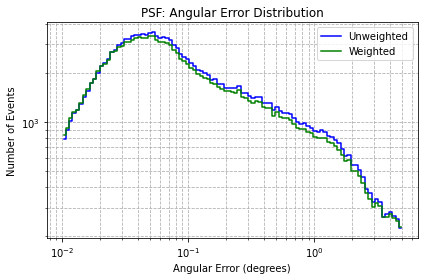

In [43]:
fig, ax = plt.subplots()
ax.plot(bin_centers, counts, drawstyle='steps-mid', color='blue', label='Unweighted')
ax.plot(bin_centers, counts_w, drawstyle='steps-mid', color='green', label='Weighted')
ax.set_xscale('log')  # <- LOG X-AXIS for log bins
ax.set_yscale('log')  # <- optional: LOG Y-AXIS
ax.set_xlabel('Angular Error (degrees)')
ax.set_ylabel('Number of Events')
ax.set_title('PSF: Angular Error Distribution')
ax.grid(True, which="both", ls="--")
ax.legend()
fig.savefig(figPath + f"psf_angular_error_distribution_exp{exponent:.1f}.png", dpi=400)
plt.tight_layout()
plt.show()

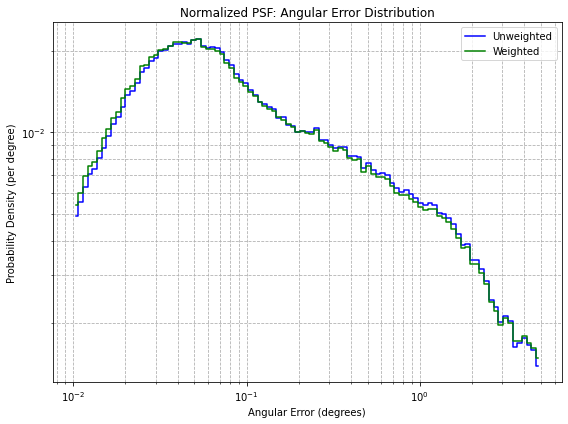

In [44]:

plt.figure(figsize=(8,6))
plt.plot(bin_centers, density, drawstyle='steps-mid', color='blue', label='Unweighted')
plt.plot(bin_centers, density_w, drawstyle='steps-mid', color='green', label='Weighted')
plt.xscale('log')  # <- LOG X-AXIS for log bins
plt.yscale('log')  # <- optional: LOG Y-AXIS
plt.xlabel('Angular Error (degrees)')
plt.ylabel('Probability Density (per degree)')
plt.title('Normalized PSF: Angular Error Distribution')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.savefig(figPath + f"psf_angular_error_normalized_distribution_exp{exponent:.1f}.png", dpi=400)
plt.show()


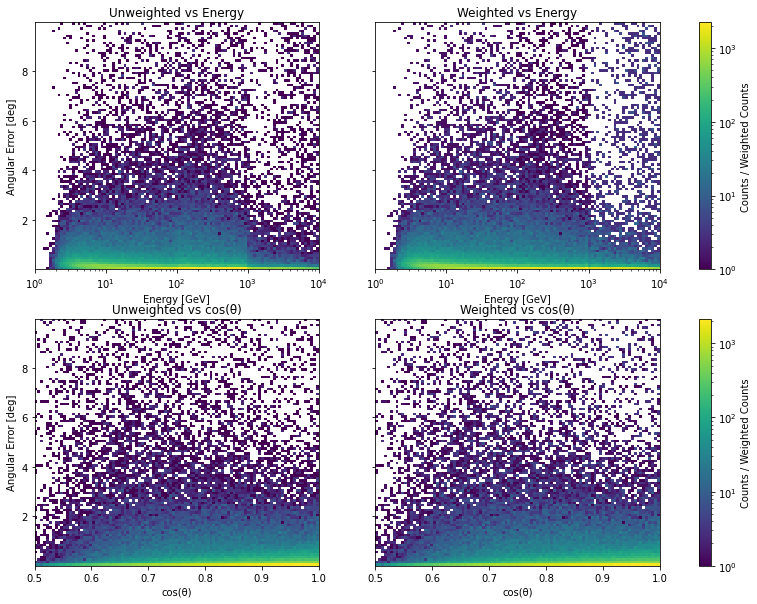

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# Define bins
nbins_E = 100
bins_E = np.logspace(np.log10(1), np.log10(1e4), nbins_E)
bins_ang = 100  # Angular error bins
bins_cosTheta = np.linspace(0.5, 1, 100)

# Setup colormap
cmap = plt.get_cmap('viridis').copy()
cmap.set_under('k', 1e-6)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)

# --- Top Left: Unweighted vs Energy ---
hist1 = axes[0, 0].hist2d(
    df['Etrue'], df['angular_error_degrees'],
    bins=[bins_E, bins_ang],
    norm='log', cmap=cmap
)
axes[0, 0].set_xscale('log')
axes[0, 0].set_xlabel("Energy [GeV]")
axes[0, 0].set_ylabel("Angular Error [deg]")
axes[0, 0].set_title("Unweighted vs Energy")
axes[0, 0].grid(False)

# --- Top Right: Weighted vs Energy ---
hist2 = axes[0, 1].hist2d(
    df['Etrue'], df['angular_error_degrees'],
    bins=[bins_E, bins_ang],
    weights=df['weight'],
    norm='log', cmap=cmap
)
axes[0, 1].set_xscale('log')
axes[0, 1].set_xlabel("Energy [GeV]")
axes[0, 1].set_title("Weighted vs Energy")
axes[0, 1].grid(False)

# Shared colorbar for top row
cbar_top = fig.colorbar(hist1[3], ax=axes[0, :], label='Counts / Weighted Counts', orientation='vertical')

# --- Bottom Left: Unweighted vs cos(Theta) ---
hist3 = axes[1, 0].hist2d(
    df['cosTheta'], df['angular_error_degrees'],
    bins=[bins_cosTheta, bins_ang],
    norm='log', cmap=cmap
)
axes[1, 0].set_xlabel("cos(θ)")
axes[1, 0].set_ylabel("Angular Error [deg]")
axes[1, 0].set_title("Unweighted vs cos(θ)")
axes[1, 0].grid(False)

# --- Bottom Right: Weighted vs cos(Theta) ---
hist4 = axes[1, 1].hist2d(
    df['cosTheta'], df['angular_error_degrees'],
    bins=[bins_cosTheta, bins_ang],
    weights=df['weight'],
    norm='log', cmap=cmap
)
axes[1, 1].set_xlabel("cos(θ)")
axes[1, 1].set_title("Weighted vs cos(θ)")
axes[1, 1].grid(False)

# Shared colorbar for bottom row
cbar_bottom = fig.colorbar(hist3[3], ax=axes[1, :], label='Counts / Weighted Counts', orientation='vertical')

fig.savefig(figPath + f"psf_angular_error_vs_energy_cosTheta_exp{exponent:.1f}.png", dpi=400)
plt.show()


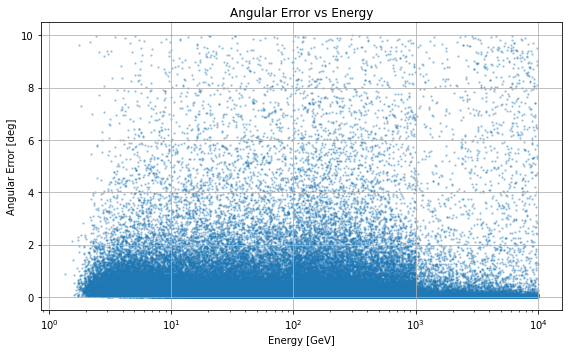

In [46]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Etrue'], df['angular_error_degrees'], s=2, alpha=0.3)
plt.xscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Angular Error [deg]")
plt.title("Angular Error vs Energy")
plt.grid(True)
plt.tight_layout()
plt.show()

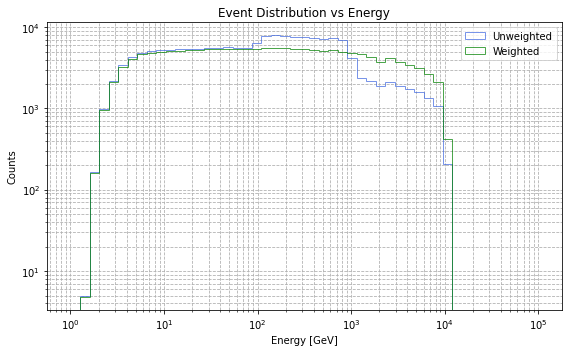

In [47]:
plt.figure(figsize=(8, 5))
plt.hist(df['Etrue'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='royalblue', histtype='step', label='Unweighted', alpha=0.7)
plt.hist(df['Etrue'], weights=df['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='green', histtype='step', label='Weighted', alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Counts")
plt.title("Event Distribution vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.savefig(figPath + f"energy_spectrum_exp{exponent:.1f}.png", dpi=400)
plt.show()

## Bin by Energy and theta

In [48]:
Emin = 1
Emax = 1e4
n_E_bins = 8
E_bins_edge = np.logspace(np.log10(Emin), np.log10(Emax), n_E_bins + 1)
E_bins_center = np.sqrt(E_bins_edge[:-1] * E_bins_edge[1:])

print("E_bins :", E_bins_center)
print("E_bins_edge :", E_bins_edge)

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 5
theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

print("theta_bins :", theta_bins_center)
print("theta_bins_edge :", theta_bins_edge)

print("Emin: ", Emin)
print("Emax: ", Emax)
print("theta_min: ", cos_theta_min)
print("theta_max: ", cos_theta_max)


# Assign bin indices
df['E_bin'] = pd.cut(df['Etrue'], bins=E_bins_edge, labels=False, include_lowest=True)
df['theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin', 'theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin'] = df['E_bin'].astype(int)
df['theta_bin'] = df['theta_bin'].astype(int)


E_bins : [1.77827941e+00 5.62341325e+00 1.77827941e+01 5.62341325e+01
 1.77827941e+02 5.62341325e+02 1.77827941e+03 5.62341325e+03]
E_bins_edge : [1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02 3.16227766e+02 1.00000000e+03 3.16227766e+03
 1.00000000e+04]
theta_bins : [0.55 0.65 0.75 0.85 0.95]
theta_bins_edge : [0.5 0.6 0.7 0.8 0.9 1. ]
Emin:  1
Emax:  10000.0
theta_min:  0.5
theta_max:  1


vmin: 9.585871399587804, vmax: 14379.0


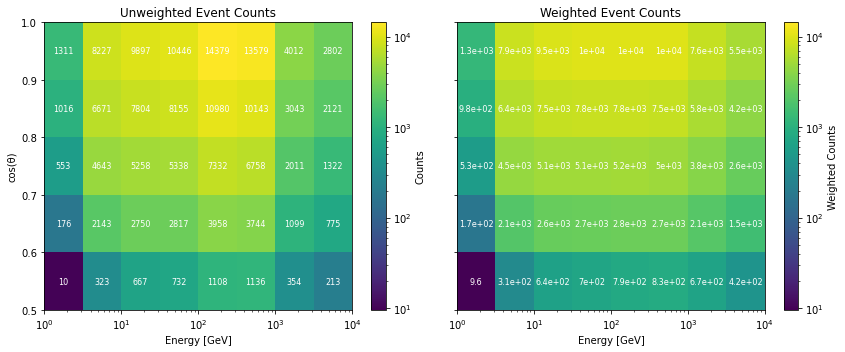

In [49]:
from matplotlib.colors import LogNorm

# Group by (E_bin, theta_bin)
grouped = df.groupby(['E_bin', 'theta_bin'])
# Unweighted count: just number of rows per bin
counts_per_bin = grouped.size().reset_index(name='count')
# Weighted count: sum of 'weight' column per bin
weighted_counts_per_bin = grouped['weight'].sum().reset_index(name='weighted_count')
# Merge into one DataFrame
count_stats = pd.merge(counts_per_bin, weighted_counts_per_bin, on=['E_bin', 'theta_bin'])
#print(count_stats)
# Empty grids
count_grid = np.zeros((n_E_bins, n_theta_bins))
weighted_count_grid = np.zeros((n_E_bins, n_theta_bins))

# Fill them
for _, row in count_stats.iterrows():
    i, j = int(row['E_bin']), int(row['theta_bin'])
    count_grid[i, j] = row['count']
    weighted_count_grid[i, j] = row['weighted_count']


# Prepare color scale (optional: shared scale)
vmin = np.nanmin([count_grid, weighted_count_grid])
vmin = max(vmin, 1e-6)  # Avoid log(0) issues
vmax = np.nanmax([count_grid, weighted_count_grid])
print(f"vmin: {vmin}, vmax: {vmax}")

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Unweighted
pcm1 = axs[0].pcolormesh(E_bins_edge, theta_bins_edge, count_grid.T,
                          shading='auto', cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax))
axs[0].set_title("Unweighted Event Counts")
axs[0].set_xlabel("Energy [GeV]")
axs[0].set_ylabel("cos(θ)")
axs[0].set_xscale('log')
# Overlay count numbers in each cell
for i in range(n_E_bins):
    for j in range(n_theta_bins):
        count = count_grid[i, j]
        if count > 0:  # Avoid writing 0 or nan
            x_center = (E_bins_edge[i] * E_bins_edge[i + 1])**0.5  # log center
            y_center = (theta_bins_edge[j] + theta_bins_edge[j + 1]) / 2
            axs[0].text(
                x_center, y_center,
                f"{int(count)}",
                color="white", ha='center', va='center', fontsize=8
            )
fig.colorbar(pcm1, ax=axs[0], label='Counts')

# Weighted
pcm2 = axs[1].pcolormesh(E_bins_edge, theta_bins_edge, weighted_count_grid.T,
                          shading='auto', cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax))
axs[1].set_title("Weighted Event Counts")
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_xscale('log')
for i in range(n_E_bins):
    for j in range(n_theta_bins):
        count = weighted_count_grid[i, j]
        if count > 0:  # Avoid writing 0 or nan
            x_center = (E_bins_edge[i] * E_bins_edge[i + 1])**0.5  # log center
            y_center = (theta_bins_edge[j] + theta_bins_edge[j + 1]) / 2
            axs[1].text(
                x_center, y_center,
                f"{count:.2g}",
                color="white", ha='center', va='center', fontsize=8)
fig.colorbar(pcm2, ax=axs[1], label='Weighted Counts')

plt.tight_layout()
plt.show()



In [50]:


def weighted_percentile(data, weights, percentiles):
    """Compute weighted percentiles."""
    data, weights = np.array(data), np.array(weights)
    sorter = np.argsort(data)
    data_sorted = data[sorter]
    weights_sorted = weights[sorter]
    cumulative_weight = np.cumsum(weights_sorted)
    total_weight = cumulative_weight[-1]
    return np.interp(np.array(percentiles) / 100 * total_weight, cumulative_weight, data_sorted)

def weighted_angular_resolution_68(group):
    angles = group['angular_error_degrees'].values
    weights = group['weight'].values
    lower, upper = weighted_percentile(angles, weights, [16, 84])
    return (upper - lower) / 2

def angular_resolution_68(x):
    lower = np.percentile(x, 16)
    upper = np.percentile(x, 84)
    return (upper - lower) / 2

resolution_per_bin = grouped['angular_error_degrees'].apply(
    angular_resolution_68
).reset_index(name='angular_resolution')
print(resolution_per_bin)

resolution_per_bin_w = grouped.apply(
    weighted_angular_resolution_68
).reset_index(name='angular_resolution_w')
print(resolution_per_bin_w)

# Save weighted angular resolution per bin to CSV
resolution_per_bin_w.to_csv(resPath + f"resolution_per_bin_weighted_exp{exponent:.1f}.csv", index=False)

# Step 4: Merge back into original dataframe
if 'angular_resolution' in df.columns:
    df = df.drop(columns='angular_resolution')
df = df.merge(resolution_per_bin, on=['E_bin', 'theta_bin'], how='left')
if 'angular_resolution_w' in df.columns:
    df = df.drop(columns='angular_resolution_w')
df = df.merge(resolution_per_bin_w, on=['E_bin', 'theta_bin'], how='left')

    E_bin  theta_bin  angular_resolution
0       0          0            0.205993
1       0          1            0.608015
2       0          2            0.459915
3       0          3            0.384433
4       0          4            0.360637
5       1          0            0.754965
6       1          1            0.530001
7       1          2            0.410330
8       1          3            0.330883
9       1          4            0.255454
10      2          0            1.410774
11      2          1            0.657658
12      2          2            0.373982
13      2          3            0.228483
14      2          4            0.195946
15      3          0            1.770550
16      3          1            0.793442
17      3          2            0.357917
18      3          3            0.215625
19      3          4            0.153979
20      4          0            1.488689
21      4          1            0.635828
22      4          2            0.342737
23      4       

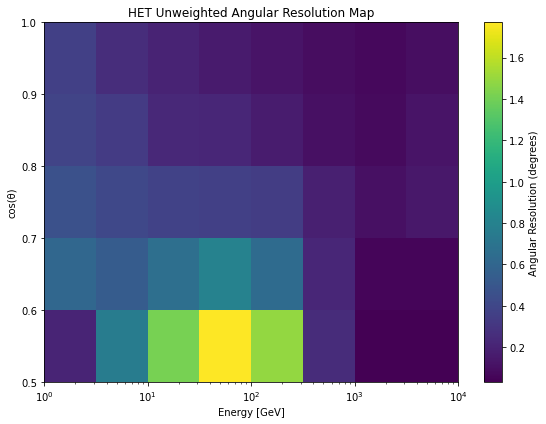

In [51]:
# Build the resolution grid directly
resolution_grid = np.full((n_E_bins, n_theta_bins), np.nan)
for _, row in resolution_per_bin.iterrows():
    resolution_grid[int(row['E_bin']), int(row['theta_bin'])] = row['angular_resolution']

resolution_grid_w = np.full((n_E_bins, n_theta_bins), np.nan)
for _, row in resolution_per_bin_w.iterrows():
    resolution_grid_w[int(row['E_bin']), int(row['theta_bin'])] = row['angular_resolution_w']


# Prepare edges for pcolormesh
E_edges = E_bins_edge

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
c = ax.pcolormesh(E_edges, theta_bins_edge, resolution_grid.T, shading='auto', cmap='viridis')

# Log scale for energy
ax.set_xscale('log')
ax.set_xlabel("Energy [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("HET Unweighted Angular Resolution Map")

# Colorbar
cb = fig.colorbar(c, ax=ax)
cb.set_label("Angular Resolution (degrees)")

plt.tight_layout()
fig.savefig(figPath+f"resolutionMap_HET_exp{exponent:.1f}.png")
plt.show()


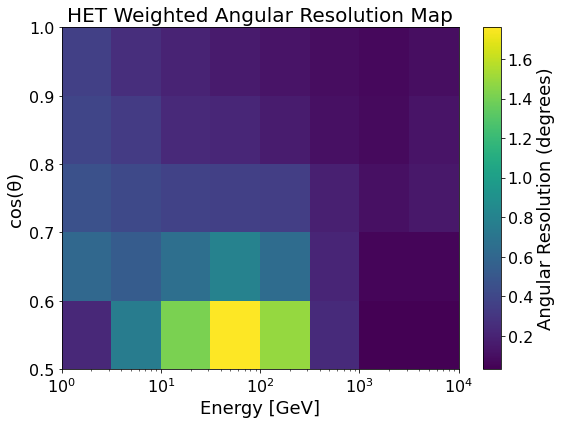

In [86]:
fig, ax = plt.subplots(figsize=(8, 6))
c = ax.pcolormesh(E_edges, theta_bins_edge, resolution_grid_w.T, shading='auto', cmap='viridis')

# Log scale for energy
ax.set_xscale('log')
ax.set_xlabel("Energy [GeV]", fontsize=18)
ax.set_ylabel("cos(θ)", fontsize=18)
ax.set_title("HET Weighted Angular Resolution Map", fontsize=20)

# Set tick label font size
ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

# Colorbar
cb = fig.colorbar(c, ax=ax)
cb.set_label("Angular Resolution (degrees)", fontsize=18)
cb.ax.tick_params(labelsize=16)

plt.tight_layout()
fig.savefig(figPath+f"resolutionMap_HET_scaled_exp{exponent:.1f}.png")
plt.show()

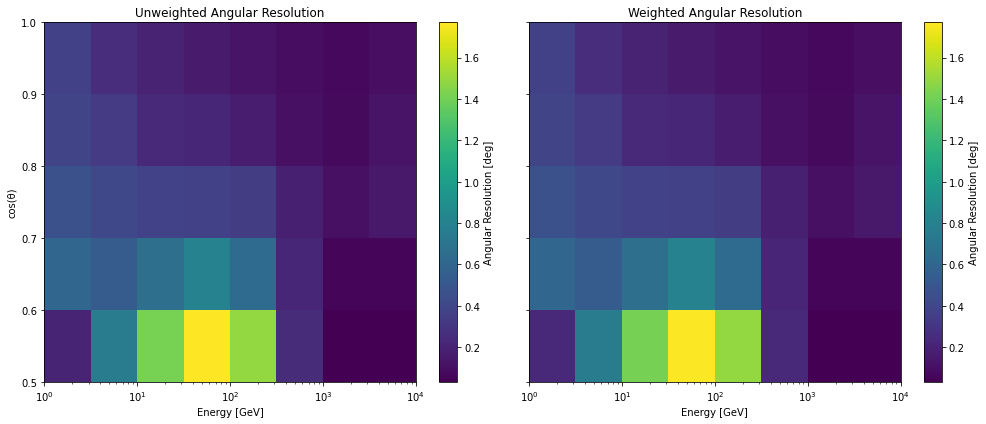

In [53]:
# Prepare color scale (optional: shared scale)
vmin = np.nanmin([resolution_grid, resolution_grid_w])
vmax = np.nanmax([resolution_grid, resolution_grid_w])

fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Unweighted
c1 = axs[0].pcolormesh(
    E_bins_edge, theta_bins_edge, resolution_grid.T,
    shading='auto', cmap='viridis', vmin=vmin, vmax=vmax
)
axs[0].set_xscale('log')
axs[0].set_xlabel("Energy [GeV]")
axs[0].set_ylabel("cos(θ)")
axs[0].set_title("Unweighted Angular Resolution")
fig.colorbar(c1, ax=axs[0], label='Angular Resolution [deg]')

# Weighted
c2 = axs[1].pcolormesh(
    E_bins_edge, theta_bins_edge, resolution_grid_w.T,
    shading='auto', cmap='viridis', vmin=vmin, vmax=vmax
)
axs[1].set_xscale('log')
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_title("Weighted Angular Resolution")
fig.colorbar(c2, ax=axs[1], label='Angular Resolution [deg]')

plt.tight_layout()
fig.savefig(figPath + f"resolutionMap_HET_unweighted_vs_weighted_exp{exponent:.1f}.png")
plt.show()

In [54]:
# # Plot angular_deviation for all 20 E, theta bins
# # Determine subplot grid size
# n_rows = n_E_bins
# n_cols = n_theta_bins

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
# fig.suptitle("Angular Deviation in Each (E_bin, θ_bin)", fontsize=16)

# # Plot each bin
# for i in range(n_E_bins):
#     for j in range(n_theta_bins):
#         ax = axes[i, j]
#         subset = df[(df['E_bin'] == i) & (df['theta_bin'] == j)]

#         if not subset.empty:
#             ax.hist(subset['angular_error_degrees'], bins=50, color='royalblue', alpha=0.7, density=True)
#             ax.set_title(f"E_bin={i}, θ_bin={j}", fontsize=9)
#         else:
#             ax.set_visible(False)

#         if i == n_rows - 1:
#             ax.set_xlabel("Angular Deviation (degrees)")
#         if j == 0:
#             ax.set_ylabel("$Density$")
#         ax.set_yscale('log')
#         ax.set_xscale('log')

# plt.tight_layout(rect=[0, 0, 1, 0.96])

## Compute scaled Angular deviation

In [55]:
df['x_p'] = df['angular_error_degrees'] / df["angular_resolution"]

In [56]:
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), sharex=True, sharey=True)
# fig.suptitle("Scaled Angular Deviation in Each (E_bin, θ_bin)", fontsize=16)

# # Plot each bin
# for i in range(n_E_bins):
#     for j in range(n_theta_bins):
#         ax = axes[i, j]
#         subset = df[(df['E_bin'] == i) & (df['theta_bin'] == j)]

#         if not subset.empty:
#             ax.hist(subset['x_p'], bins=50, color='royalblue', alpha=0.7, density=True)
#             ax.set_title(f"E_bin={i}, θ_bin={j}", fontsize=9)
#         else:
#             ax.set_visible(False)

#         if i == n_rows - 1:
#             ax.set_xlabel("Scaled Angular Deviation $x_p$")
#         if j == 0:
#             ax.set_ylabel("$Density$")
#         ax.set_yscale('log')
#         ax.set_xscale('log')

# plt.tight_layout(rect=[0, 0, 1, 0.96])
# plt.show()

## Fit with double king

In [57]:
from scipy.stats import chi2

def king(xp, sigma, gamma):
    factor1 = 1/(2*np.pi*sigma*sigma)
    factor2 = (1 - 1/gamma)
    factor3 = (1 + 0.5*(1/gamma)*((xp/sigma)**2))**(-gamma)

    return factor1 * factor2 * factor3

def x_king(xp, sigma, gamma):
    return xp * king(xp, sigma, gamma)


def doubleKing(xp, A, F, sigma_c, gamma_c, sigma_t, gamma_t) :

    return A *(F * x_king(xp, sigma_c, gamma_c) + (1-F) * x_king(xp, sigma_t, gamma_t))

def chisq(data, model, error, dofs):
    residuals = np.abs(data - model)
    chi_squared = np.sum((residuals)**2 / (error**2))
    p_value = 1 - chi2.cdf(chi_squared, dofs)
    return chi_squared, p_value

In [82]:
from scipy.optimize import curve_fit
# Select a specific bin (E_bin and theta_bin)
E_bin = 2
theta_bin = 1
n_bins = 30
subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin)] 

xpMin = subset["x_p"].min()
xpMax = subset["x_p"].max()
bins = np.logspace(np.log10(xpMin), np.log10(xpMax), n_bins)
counts, bin_edges = np.histogram(subset['x_p'], bins=bins)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
bin_widths = bin_edges[1:] - bin_edges[:-1]
errors = np.sqrt(counts)

# Normalize counts and errors
total = np.sum(counts)
print(f"Total number of counts in subset : {total}")
counts_norm = counts / (bin_centers * total) 
errors_norm = errors / (bin_centers * total)

epsilon = 1e-5
valid = (counts > 5) & (counts_norm > epsilon) & (errors_norm > epsilon)


# ---- Initial guesses ----
A_init = 0.2
F_init = 0.8
gamma_init = 1.2
std = np.std(subset['x_p'])


p0 = [ A_init, # A 
    F_init,        # F
    std, gamma_init,  # sigma_c, gamma_c,
    std, gamma_init   # sigma_t, gamma_t
]

#p0 = [430.72318702228625, 0.0007544318960550428, 0.0743047489922788, 0.999855853967373, 0.28605125531570047, 1.278022587242577]

print(f"Initial parameters : {p0}")

bounds = ([0, 0.5, 0, 1.00001, 0, 1.0001],
          [10, 1, 10, 10, 10, 10]
          )

bin_centers_valid = bin_centers[valid]
counts_norm_valid = counts_norm[valid]
errors_norm_valid = errors_norm[valid]


popt, pcov = curve_fit(
        doubleKing,
        bin_centers_valid,
        counts_norm_valid,
        p0=p0,
        sigma=errors_norm_valid,
        bounds=bounds,
        absolute_sigma=True,
        maxfev=20000
    )

fit_vals = doubleKing(bin_centers_valid, *popt)
fit_vals_counts = fit_vals * (bin_widths[valid] * total)  # Convert back to counts
# Compute chi-squared
ndof = len(bin_centers[valid]) - len(popt)  # number of degrees of freedom
chi_squared, p_val = chisq(counts_norm_valid, fit_vals, errors_norm_valid, ndof)
chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"

Total number of counts in subset : 2748
Initial parameters : [0.2, 0.8, 2.207342625663544, 1.2, 2.207342625663544, 1.2]


Optimised parameters :  1.9375744908324395 0.5847026101125005 0.05439270780286127 1.8894687257662774 0.4939437374311362 1.4074148467625291


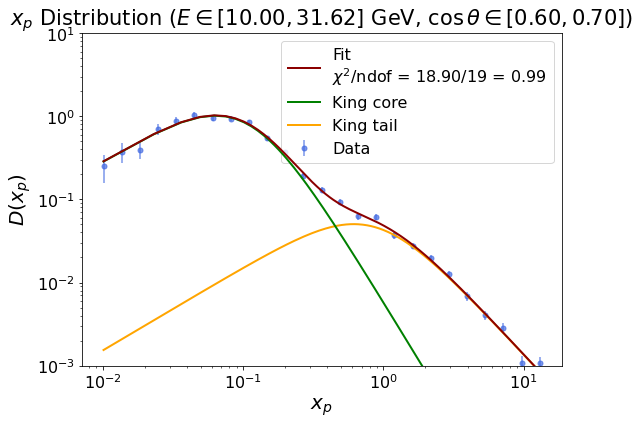

In [90]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(bin_centers_valid, counts_norm_valid, yerr=errors_norm_valid, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=5)

if popt is not None:
    x_fit = np.linspace(bin_centers_valid[0], bin_centers_valid[-1], 1000)
    y_fit = doubleKing(x_fit, *popt)
    ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}', zorder=10)
    A, F, sigma_c, gamma_c, sigma_t, gamma_t = popt

    y_fit1 = A*(F * x_king(x_fit, sigma_c, gamma_c))
    y_fit2 = A *(1 - F) * x_king(x_fit, sigma_t, gamma_t)

    ax.plot(x_fit, y_fit1, color='green', lw=2, label='King core', zorder=9)
    ax.plot(x_fit, y_fit2, color='orange', lw=2, label='King tail', zorder=8)

    print(f"Optimised parameters : ", *popt)

Ebin_low = E_bins_edge[E_bin]
Ebin_up = E_bins_edge[E_bin+1]
cosTheta_low = theta_bins_edge[theta_bin]
cosTheta_up = theta_bins_edge[theta_bin + 1]

ax.set_title(f"$x_p$ Distribution ($E\\in [{Ebin_low:.2f}, {Ebin_up:.2f}]$ GeV, $\\cos\\theta \\in [{cosTheta_low:.2f}, {cosTheta_up:.2f}]$)", fontsize=21)
ax.set_xlabel("$x_p$", fontsize=20)
ax.set_ylabel("$D(x_p)$", fontsize=20)
ax.set_yscale('log')
ax.set_xscale("log")
ax.set_ylim(1e-3, 10)
ax.legend(fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=16)
plt.tight_layout()
plt.show()

## Fit all bins

In [63]:
class EmptyBinException(Exception):
    """Custom exception for empty bins."""
    pass

def get_histogram(subset, bins):
    
    counts, bin_edges = np.histogram(subset['x_p'], bins=bins)

    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    errors = np.sqrt(counts)

    return bin_centers, counts, errors

def get_histogram_normed(subset, bins):

    bin_centers, counts, errors = get_histogram(subset, bins)
    # Normalize counts and errors
    total = np.sum(counts)
    print(f"Total number of counts in subset : {total}")
    counts_norm = counts / (bin_centers * total) 
    errors_norm = errors / (bin_centers * total)

    return bin_centers, counts, errors, counts_norm, errors_norm


def fit_xp_bin(subset, bins) :
    
    bin_centers, counts, errors, counts_norm, errors_norm = get_histogram_normed(subset, bins)

     
    epsilon = 1e-5
    valid = (counts > 5)

    bin_centers_valid = bin_centers[valid]
    counts_norm_valid = counts_norm[valid]
    errors_norm_valid = errors_norm[valid]

    if len(bin_centers_valid) == 0 :
        raise EmptyBinException

    popt, pcov = curve_fit(
            doubleKing,
            bin_centers_valid,
            counts_norm_valid,
            p0=p0,
            sigma=errors_norm_valid,
            bounds=bounds,
            absolute_sigma=True,
            maxfev=20000
        )

    fit_vals = doubleKing(bin_centers_valid, *popt)
    # Compute chi-squared
    ndof = len(bin_centers_valid) - len(popt)  # number of degrees of freedom
    chi_squared, p_val = chisq(counts_norm_valid, fit_vals, errors_norm_valid, ndof)
    
    return popt, chi_squared, p_val, bin_centers_valid, counts_norm_valid, errors_norm_valid

In [64]:
fig, axes = plt.subplots(n_E_bins, n_theta_bins, figsize=(n_E_bins * 4, n_theta_bins * 3), sharex=True, sharey=True)
fig.suptitle("Scaled Angular Deviation x_p in Each (E_bin, θ_bin)", fontsize=16)

for E_bin in range(len(E_bins_center)):
    for theta_bin in range(len(theta_bins_center)):
        print(f'Processing E_bin={E_bin}, theta_bin={theta_bin}')

        subset = df[(df['E_bin'] == E_bin) & (df['theta_bin'] == theta_bin)] 
        n_bins = min(30, max(10, len(subset) // 5))
        print(f"Number of bins generated : {n_bins}")

        xpMin = subset["x_p"].min()
        xpMax = subset["x_p"].max()
        bins = np.logspace(np.log10(xpMin), np.log10(xpMax), n_bins)

        ax = axes[E_bin, theta_bin]
        
        ax.set_title(f"E_bin={E_bin}, θ_bin={theta_bin}", fontsize=16)
        ax.set_xlabel("$x_p$")
        ax.set_ylabel("$D(x_p)$")
        ax.set_yscale('log')
        ax.set_xscale("log")
        ax.set_ylim(1e-3, 10)


        try :
            popt, chi_squared, p_val, bin_centers, counts_norm, errors_norm = fit_xp_bin(subset, bins)
            ndof = len(bin_centers) - len(popt)  # number of degrees of freedom
            chi_squared_str = f"$\chi^2$/ndof = {chi_squared:.2f}/{ndof} = {chi_squared/ndof:.2f}"

        except EmptyBinException as e:
            print(e)
            popt = None
            bin_centers, counts, errors, counts_norm, errors_norm = get_histogram_normed(subset, bins)

        ax.errorbar(bin_centers, counts_norm, yerr=errors_norm, fmt='o', color='royalblue', alpha=0.7, label="Data", markersize=3)


        if popt is not None: 
            
            x_fit = np.linspace(bin_centers[0], bin_centers[-1], 1000)
            y_fit = doubleKing(x_fit, *popt)

            ax.plot(x_fit, y_fit, color='darkred', lw=2, label=f'Fit\n{chi_squared_str}')
            A, F, sigma_c, gamma_c, sigma_t, gamma_t = popt

            y_fit1 = A*(F * x_king(x_fit, sigma_c, gamma_c))
            y_fit2 = A *(1 - F) * x_king(x_fit, sigma_t, gamma_t)

            # Apply the masks to plot only the regions where the conditions are satisfied
            ax.plot(x_fit, y_fit1, color='green', lw=2, label='King core')
            ax.plot(x_fit, y_fit2, color='orange', lw=2, label='King tail')

            
            ax.legend()

fig.tight_layout()
fig.savefig(figPath+"xp_HET_fits_allbins.png")

plt.show()
            

Processing E_bin=0, theta_bin=0
Number of bins generated : 10
Total number of counts in subset : 10

Total number of counts in subset : 10
Processing E_bin=0, theta_bin=1
Number of bins generated : 30
Total number of counts in subset : 174
Processing E_bin=0, theta_bin=2
Number of bins generated : 30
Total number of counts in subset : 551
Processing E_bin=0, theta_bin=3
Number of bins generated : 30
Total number of counts in subset : 1015
Processing E_bin=0, theta_bin=4
Number of bins generated : 30
Total number of counts in subset : 1311
Processing E_bin=1, theta_bin=0
Number of bins generated : 30
Total number of counts in subset : 322
Processing E_bin=1, theta_bin=1
Number of bins generated : 30
Total number of counts in subset : 2142
Processing E_bin=1, theta_bin=2
Number of bins generated : 30
Total number of counts in subset : 4643
Processing E_bin=1, theta_bin=3
Number of bins generated : 30
Total number of counts in subset : 6670
Processing E_bin=1, theta_bin=4
Number of bins g

KeyboardInterrupt: 